# 03 — ResNet18 transfer learning
GPU runtime required. Two stages: (1) train only the new classification head, (2) fine-tune the whole network at a lower LR.
Evaluates on **validation only**; the test set stays untouched until final evaluation.

In [2]:
KAGGLE_DATASET = "sainibharat10/neurovision-brain-mri"
import os, glob, shutil, zipfile
DATA, ART = "/content/data", "/content/artifacts"
os.makedirs(ART, exist_ok=True)
!pip -q install kagglehub
import kagglehub

def find_root(p):
    hits = glob.glob(f"{p}/**/train", recursive=True)
    return os.path.dirname(hits[0]) if hits else None

if not os.path.isdir(f"{DATA}/train"):
    try:
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception:
        kagglehub.login()
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    root = find_root(path)
    if root is None:
        for z in glob.glob(f"{path}/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        for z in glob.glob("/content/_raw/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        root = find_root("/content/_raw")
    assert root, "train/ folder not found"
    shutil.copytree(root, DATA, dirs_exist_ok=True)
print(sorted(os.listdir(DATA)))

100%|██████████| 107M/107M [00:00<00:00, 132MB/s] 

Extracting files...


['test', 'train', 'val']


In [3]:
import json, time, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T, models
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", device)

SPLITS = ["train", "val", "test"]
CLASSES = sorted(os.listdir(f"{DATA}/train"))
rows = [(s, c, f"{DATA}/{s}/{c}/{f}") for s in SPLITS for c in CLASSES for f in os.listdir(f"{DATA}/{s}/{c}")]
df = pd.DataFrame(rows, columns=["split", "cls", "path"])   # near-duplicate check: false alarm, keep all images

device: cuda


## Data: decode + resize once, keep in RAM (fast epochs)

In [4]:
IMG = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]     # ImageNet stats (required for pretrained weights)

def load(p): return np.asarray(Image.open(p).convert("RGB").resize((IMG, IMG), Image.BILINEAR))
def make_cache(frame):
    with ThreadPoolExecutor(8) as ex: xs = list(ex.map(load, frame.path))
    return torch.from_numpy(np.stack(xs)).permute(0, 3, 1, 2).contiguous(), [CLASSES.index(c) for c in frame.cls]

aug = T.Compose([T.RandomRotation(10), T.RandomAffine(0, translate=(0.05, 0.05)), T.ColorJitter(0.1, 0.1)])
norm = T.Normalize(MEAN, STD)

class CachedDS(Dataset):
    def __init__(self, X, y, train): self.X, self.y, self.train = X, y, train
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = self.X[i]
        if self.train: x = aug(x)
        return norm(x.float() / 255), self.y[i]

cache = {s: make_cache(df[df.split == s]) for s in SPLITS}
ds = {s: CachedDS(*cache[s], train=(s == "train")) for s in SPLITS}
dl = {s: DataLoader(ds[s], batch_size=32, shuffle=(s == "train"), num_workers=2,
                    persistent_workers=True, pin_memory=True) for s in SPLITS}
n = np.bincount(ds["train"].y, minlength=len(CLASSES))
class_weights = torch.tensor(n.sum() / (len(CLASSES) * n), dtype=torch.float32).to(device)
print({s: len(ds[s]) for s in SPLITS})

{'train': 4160, 'val': 892, 'test': 889}


## Model: ImageNet-pretrained ResNet18 with a new 4-class head

In [5]:
def build_resnet18(n_classes=4):
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, n_classes))
    return m

model = build_resnet18(len(CLASSES)).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")   # Grad-CAM target later: model.layer4[-1]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


11,178,564 parameters


## Training utilities (best checkpoint by validation macro-F1)

In [6]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval(); loss_sum, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            out = model(x); loss = criterion(out, y)
        loss_sum += loss.item() * len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return loss_sum / len(ys), f1_score(ys, ps, average="macro"), np.mean(np.array(ys) == np.array(ps)), ys, ps

def fit(model, name, params, lr, epochs, patience, weight_decay=1e-4, freeze_bn=False):
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    scaler = torch.amp.GradScaler(enabled=(device == "cuda"))
    hist, best, bad = [], -1, 0
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train(); tl, tc, tn = 0.0, 0, 0
        if freeze_bn:                                   # keep BatchNorm statistics fixed while backbone is frozen
            for m in model.modules():
                if isinstance(m, nn.BatchNorm2d): m.eval()
        for x, y in dl["train"]:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
                out = model(x); loss = criterion(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        vl, vf1, vacc, _, _ = evaluate(model, dl["val"], criterion)
        sched.step(vf1)
        hist.append(dict(epoch=ep, train_loss=tl / tn, train_acc=tc / tn, val_loss=vl, val_acc=vacc,
                         val_macro_f1=vf1, lr=opt.param_groups[0]["lr"]))
        flag = ""
        if vf1 > best:
            best, bad, flag = vf1, 0, " *saved*"
            torch.save({"model": model.state_dict(), "classes": CLASSES, "val_macro_f1": vf1, "epoch": ep},
                       f"{ART}/{name}_best.pth")
        else:
            bad += 1
        print(f"ep {ep:02d} | train loss {tl/tn:.4f} acc {tc/tn:.3f} | val loss {vl:.4f} acc {vacc:.3f} "
              f"F1 {vf1:.3f} | {time.time()-t0:.0f}s{flag}")
        if bad >= patience: print("early stopping"); break
    json.dump(hist, open(f"{ART}/{name}_history.json", "w"))
    return pd.DataFrame(hist)

## Stage 1 — train the new head only (backbone frozen)

In [7]:
for p in model.parameters(): p.requires_grad = False
for p in model.fc.parameters(): p.requires_grad = True
h1 = fit(model, "resnet18_stage1", params=model.fc.parameters(), lr=1e-3, epochs=5, patience=5, freeze_bn=True)

ep 01 | train loss 0.9584 acc 0.586 | val loss 0.7221 acc 0.732 F1 0.705 | 30s *saved*
ep 02 | train loss 0.7016 acc 0.721 | val loss 0.6569 acc 0.779 F1 0.776 | 27s *saved*
ep 03 | train loss 0.6209 acc 0.757 | val loss 0.5808 acc 0.789 F1 0.792 | 28s *saved*
ep 04 | train loss 0.5980 acc 0.766 | val loss 0.5561 acc 0.805 F1 0.804 | 28s *saved*
ep 05 | train loss 0.5727 acc 0.770 | val loss 0.5758 acc 0.803 F1 0.798 | 27s


## Stage 2 — fine-tune the whole network at a lower learning rate

In [8]:
model.load_state_dict(torch.load(f"{ART}/resnet18_stage1_best.pth", map_location=device)["model"])
for p in model.parameters(): p.requires_grad = True
h2 = fit(model, "resnet18", params=model.parameters(), lr=1e-4, epochs=25, patience=6)

ep 01 | train loss 0.4609 acc 0.831 | val loss 0.2310 acc 0.932 F1 0.929 | 29s *saved*
ep 02 | train loss 0.1833 acc 0.934 | val loss 0.1744 acc 0.951 F1 0.947 | 28s *saved*
ep 03 | train loss 0.1075 acc 0.960 | val loss 0.1087 acc 0.966 F1 0.966 | 28s *saved*
ep 04 | train loss 0.0834 acc 0.969 | val loss 0.1462 acc 0.954 F1 0.951 | 28s
ep 05 | train loss 0.0672 acc 0.978 | val loss 0.1774 acc 0.948 F1 0.945 | 28s
ep 06 | train loss 0.0686 acc 0.974 | val loss 0.1101 acc 0.959 F1 0.959 | 28s
ep 07 | train loss 0.0295 acc 0.988 | val loss 0.0987 acc 0.962 F1 0.960 | 30s
ep 08 | train loss 0.0215 acc 0.992 | val loss 0.0952 acc 0.966 F1 0.965 | 31s
ep 09 | train loss 0.0176 acc 0.994 | val loss 0.0955 acc 0.965 F1 0.965 | 29s
early stopping


## Curves (stage 2)

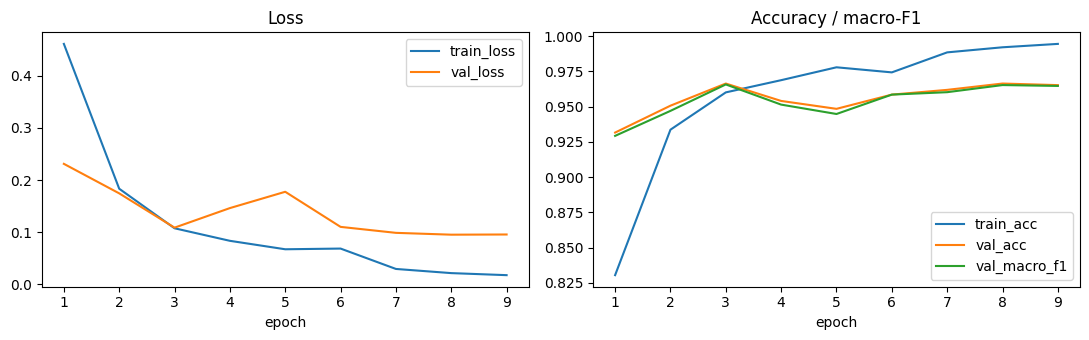

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
h2.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax[0], title="Loss")
h2.plot(x="epoch", y=["train_acc", "val_acc", "val_macro_f1"], ax=ax[1], title="Accuracy / macro-F1")
plt.tight_layout(); plt.show()

## Validation report with the best checkpoint (test set still untouched)

best epoch: 3
ResNet18  VAL accuracy 0.9664 | macro-F1 0.9657
Baseline  VAL accuracy 0.9204 | macro-F1 0.9222   (from notebook 02)

              precision    recall  f1-score   support

      glioma      0.979     0.973     0.976       329
  meningioma      0.950     0.941     0.946       222
    no_tumor      0.959     0.983     0.971       118
   pituitary      0.969     0.973     0.971       223

    accuracy                          0.966       892
   macro avg      0.964     0.968     0.966       892
weighted avg      0.966     0.966     0.966       892



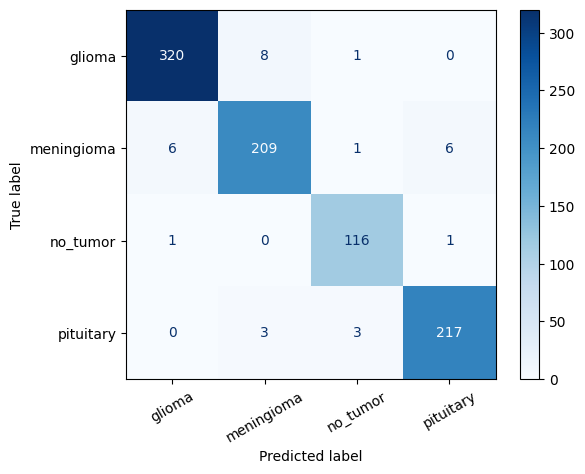

In [10]:
ck = torch.load(f"{ART}/resnet18_best.pth", map_location=device)
model.load_state_dict(ck["model"]); print("best epoch:", ck["epoch"])
_, f1, acc, ys, ps = evaluate(model, dl["val"], nn.CrossEntropyLoss(weight=class_weights))
print(f"ResNet18  VAL accuracy {acc:.4f} | macro-F1 {f1:.4f}")
print("Baseline  VAL accuracy 0.9204 | macro-F1 0.9222   (from notebook 02)\n")
print(classification_report(ys, ps, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(ys, ps), display_labels=CLASSES).plot(cmap="Blues", xticks_rotation=30)
plt.show()

## Look at the mistakes (validation)

30 misclassified of 892


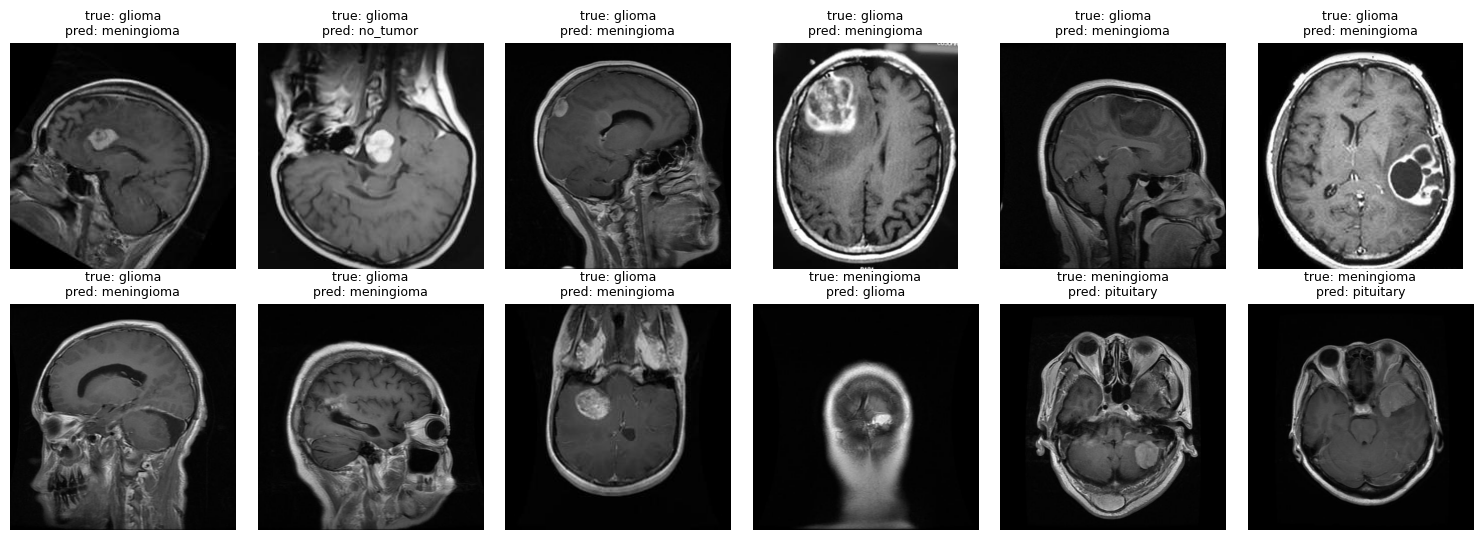

In [11]:
val_paths = df[df.split == "val"].path.tolist()     # same order as the cached val set
wrong = [i for i, (a, b) in enumerate(zip(ys, ps)) if a != b]
print(len(wrong), "misclassified of", len(ys))
fig, ax = plt.subplots(2, 6, figsize=(15, 5.5))
for a, i in zip(ax.ravel(), wrong[:12]):
    a.imshow(Image.open(val_paths[i]).convert("RGB")); a.axis("off")
    a.set_title(f"true: {CLASSES[ys[i]]}\npred: {CLASSES[ps[i]]}", fontsize=9)
plt.tight_layout(); plt.show()

## Save and download artifacts

In [12]:
json.dump(CLASSES, open(f"{ART}/class_names.json", "w"))
from google.colab import files
shutil.make_archive("/content/neurovision_resnet18", "zip", ART)
files.download("/content/neurovision_resnet18.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>